<a href="https://colab.research.google.com/github/Seif-1/airbnb_new_user_bookings/blob/main/airbnb_new_user_bookings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option("display.max_columns",None)
!pip install MissForest
!pip install --upgrade lightgbm missforest pandas

In [ ]:
train_users = pd.read_csv("/content/drive/MyDrive/train_users_2.csv")
sessions = pd.read_csv("/content/drive/MyDrive/sessions.csv")
test_users = pd.read_csv("/content/drive/MyDrive/test_users.csv")

# **Data Exploration**

In [ ]:
train_users.head(10)

,id,date_account_created,timestamp_first_active,date_first_booking,gender,age,signup_method,signup_flow,language,affiliate_channel,affiliate_provider,first_affiliate_tracked,signup_app,first_device_type,first_browser,country_destination
0,gxn3p5htnn,2010-06-28,20090319043255,NaN,-unknown-,NaN,facebook,0,en,direct,direct,untracked,Web,Mac Desktop,Chrome,NDF
1,820tgsjxq7,2011-05-25,20090523174809,NaN,MALE,38.0,facebook,0,en,seo,google,untracked,Web,Mac Desktop,Chrome,NDF
2,4ft3gnwmtx,2010-09-28,20090609231247,2010-08-02,FEMALE,56.0,basic,3,en,direct,direct,untracked,Web,Windows Desktop,IE,US
3,bjjt8pjhuk,2011-12-05,20091031060129,2012-09-08,FEMALE,42.0,facebook,0,en,direct,direct,untracked,Web,Mac Desktop,Firefox,other
4,87mebub9p4,2010-09-14,20091208061105,2010-02-18,-unknown-,41.0,basic,0,en,direct,direct,untracked,Web,Mac Desktop,Chrome,US
5,osr2jwljor,2010-01-01,20100101215619,2010-01-02,-unknown-,NaN,basic,0,en,other,other,omg,Web,Mac Desktop,Chrome,US
6,lsw9q7uk0j,2010-01-02,20100102012558,2010-01-05,FEMALE,46.0,basic,0,en,other,craigslist,untracked,Web,Mac Desktop,Safari,US
7,0d01nltbrs,2010-01-03,20100103191905,2010-01-13,FEMALE,47.0,basic,0,en,direct,direct,omg,Web,Mac Desktop,Safari,US
8,a1vcnhxeij,2010-01-04,20100104004211,2010-07-29,FEMALE,50.0,basic,0,en,other,craigslist,untracked,Web,Mac Desktop,Safari,US
9,6uh8zyj2gn,2010-01-04,20100104023758,2010-01-04,-unknown-,46.0,basic,0,en,other,craigslist,omg,Web,Mac Desktop,Firefox,US


In [ ]:
train_users.shape

(213451, 16)

In [ ]:
train_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 213451 entries, 0 to 213450
Data columns (total 16 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       213451 non-null  object 
 1   date_account_created     213451 non-null  object 
 2   timestamp_first_active   213451 non-null  int64  
 3   date_first_booking       88908 non-null   object 
 4   gender                   213451 non-null  object 
 5   age                      125461 non-null  float64
 6   signup_method            213451 non-null  object 
 7   signup_flow              213451 non-null  int64  
 8   language                 213451 non-null  object 
 9   affiliate_channel        213451 non-null  object 
 10  affiliate_provider       213451 non-null  object 
 11  first_affiliate_tracked  207386 non-null  object 
 12  signup_app               213451 non-null  object 
 13  first_device_type        213451 non-null  object 
 14  firs

In [ ]:
train_users['language'].value_counts()

,count
language,
en,206314
zh,1632
fr,1172
es,915
ko,747
de,732
it,514
ru,389
pt,240


In [ ]:
train_users.drop('timestamp_first_active', axis=1, inplace=True)
train_users.drop('language', axis=1, inplace=True)

In [ ]:
(train_users.isna().sum().sort_values(ascending=False))/train_users.shape[0]

,0
date_first_booking,0.583473
age,0.412226
first_affiliate_tracked,0.028414
id,0.000000
date_account_created,0.000000
gender,0.000000
signup_method,0.000000
signup_flow,0.000000
affiliate_channel,0.000000
affiliate_provider,0.000000


In [ ]:
for col in train_users.columns:
    null_count = train_users[col].isnull().sum()
    if null_count > 0:
        print(f"Column '{col}' has {null_count} null values.")
    else:
        print(f"Column '{col}' has NO null values.")

Column 'id' has NO null values.
Column 'date_account_created' has NO null values.
Column 'date_first_booking' has 124543 null values.
Column 'gender' has NO null values.
Column 'age' has 87990 null values.
Column 'signup_method' has NO null values.
Column 'signup_flow' has NO null values.
Column 'affiliate_channel' has NO null values.
Column 'affiliate_provider' has NO null values.
Column 'first_affiliate_tracked' has 6065 null values.
Column 'signup_app' has NO null values.
Column 'first_device_type' has NO null values.
Column 'first_browser' has NO null values.
Column 'country_destination' has NO null values.


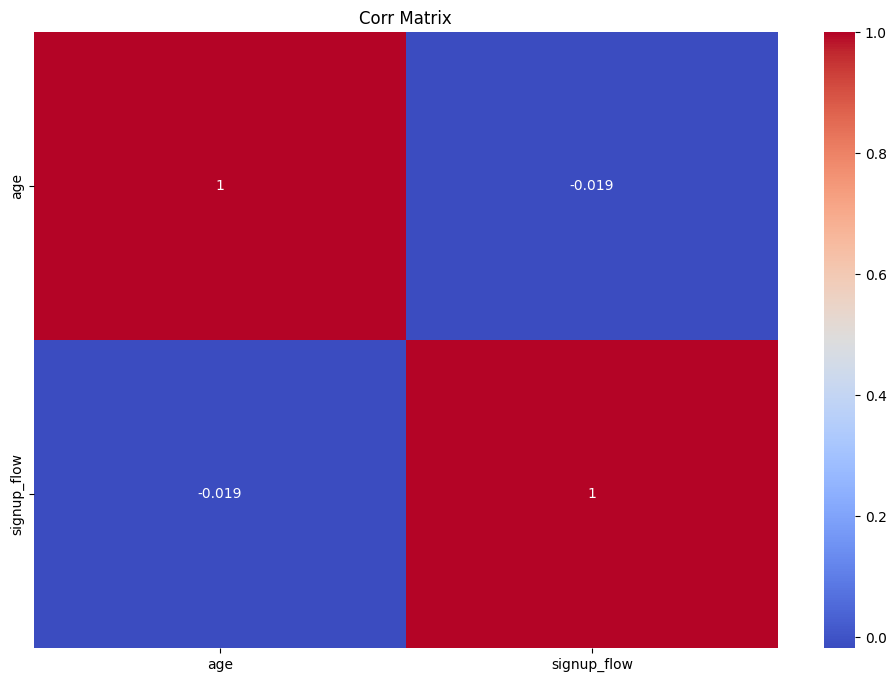

In [ ]:
numeric_features = train_users.select_dtypes(include=['number'])
corr_matrix =numeric_features.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Corr Matrix')
plt.show()

In [ ]:
train_users['date_account_created'] = pd.to_datetime(train_users['date_account_created'])
train_users['year_created'] = train_users['date_account_created'].dt.year
train_users['month_created'] = train_users['date_account_created'].dt.month
train_users['day_created'] = train_users['date_account_created'].dt.day

In [ ]:
train_users = train_users.drop('date_account_created', axis=1)

In [ ]:
train_users['date_first_booking'] = pd.to_datetime(train_users['date_first_booking'])
train_users['year_booking'] = train_users['date_first_booking'].dt.year
train_users['month_booking'] = train_users['date_first_booking'].dt.month
train_users['day_booking'] = train_users['date_first_booking'].dt.day
train_users['date_first_booking']=pd.to_datetime(train_users['date_first_booking'])
train_users.drop('date_first_booking', axis=1, inplace=True)

# Clean Data

In [ ]:
train_users

,id,date_first_booking,gender,age,signup_method,signup_flow,affiliate_channel,affiliate_provider,first_affiliate_tracked,signup_app,first_device_type,first_browser,country_destination,year_created,month_created,day_created,year_booking,month_booking,day_booking
0,gxn3p5htnn,NaT,-unknown-,NaN,facebook,0,direct,direct,untracked,Web,Mac Desktop,Chrome,NDF,2010,6,28,NaN,NaN,NaN
1,820tgsjxq7,NaT,MALE,38.0,facebook,0,seo,google,untracked,Web,Mac Desktop,Chrome,NDF,2011,5,25,NaN,NaN,NaN
2,4ft3gnwmtx,2010-08-02,FEMALE,56.0,basic,3,direct,direct,untracked,Web,Windows Desktop,IE,US,2010,9,28,2010.0,8.0,2.0
3,bjjt8pjhuk,2012-09-08,FEMALE,42.0,facebook,0,direct,direct,untracked,Web,Mac Desktop,Firefox,other,2011,12,5,2012.0,9.0,8.0
4,87mebub9p4,2010-02-18,-unknown-,41.0,basic,0,direct,direct,untracked,Web,Mac Desktop,Chrome,US,2010,9,14,2010.0,2.0,18.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
213446,zxodksqpep,NaT,MALE,32.0,basic,0,sem-brand,google,omg,Web,Mac Desktop,Safari,NDF,2014,6,30,NaN,NaN,NaN
213447,mhewnxesx9,NaT,-unknown-,NaN,basic,0,direct,direct,linked,Web,Windows Desktop,Chrome,NDF,2014,6,30,NaN,NaN,NaN
213448,6o3arsjbb4,NaT,-unknown-,32.0,basic,0,direct,direct,untracked,Web,Mac Desktop,Firefox,NDF,2014,6,30,NaN,NaN,NaN
213449,jh95kwisub,NaT,-unknown-,NaN,basic,25,other,other,tracked-other,iOS,iPhone,Mobile Safari,NDF,2014,6,30,NaN,NaN,NaN


In [ ]:
train_users['date_first_booking'].isna().sum()/train_users.shape[0]

0.5834734904029496

**Two Ways to solve the missing values in date_first_booking col**

*first way*

In [ ]:
"date_first_booking has 58% Missing Values so we can use Binary indecated"

#train_users['tick_booked'] = train_users['date_first_booking'].apply(lambda x: 1 if pd.notnull(x) else 0 )

'date_first_booking has 58% Missing Values so we can use Binary indecated'

In [ ]:
#train_users.drop('date_first_booking', axis=1, inplace=True)

In [ ]:
#train_users['tick_booked'].value_counts()

*Second way*

In [ ]:
from missforest import MissForest
impute_cols = ['year_booking', 'month_booking', 'day_booking']
df_impute = train_users[impute_cols].copy()
df_impute = df_impute.astype(float)
mf = MissForest()
X_imputed = mf.fit_transform(df_impute)
train_users[impute_cols] = X_imputed
print(train_users[impute_cols].isna().sum())

/usr/local/lib/python3.11/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.11/dist-packages/missforest/missforest.py:333: UserWarning: Label encoding is no longer performed by default. Users will have to perform categorical features encoding by themselves.
  warnings.warn("Label encoding is no longer performed by default. "
 40%|████      | 2/5 [00:21<00:30, 10.16s/it]/usr/local/lib/python3.11/dist-packages/missforest/missforest.py:303: UserWarning: NRMSE increased.
  warnings.warn("NRMSE increased.")
/usr/local/lib/python3.11/dist-packages/missforest/missforest.py:453: UserWarning: Stopping criterion triggered during fitting. Before last imputation matrix will be returned.
  warnings.warn(
 40%|████      | 2/5 [00:28<00:42

year_booking     0
month_booking    0
day_booking      0
dtype: int64


In [ ]:
train_users[['year_booking', 'month_booking', 'day_booking']] = train_users[['year_booking', 'month_booking', 'day_booking']].astype(int)

In [ ]:
train_users

,id,date_first_booking,gender,age,signup_method,signup_flow,affiliate_channel,affiliate_provider,first_affiliate_tracked,signup_app,first_device_type,first_browser,country_destination,year_created,month_created,day_created,year_booking,month_booking,day_booking
0,gxn3p5htnn,NaT,-unknown-,NaN,facebook,0,direct,direct,untracked,Web,Mac Desktop,Chrome,NDF,2010,6,28,2013,5,15
1,820tgsjxq7,NaT,MALE,38.0,facebook,0,seo,google,untracked,Web,Mac Desktop,Chrome,NDF,2011,5,25,2013,5,15
2,4ft3gnwmtx,2010-08-02,FEMALE,56.0,basic,3,direct,direct,untracked,Web,Windows Desktop,IE,US,2010,9,28,2010,8,2
3,bjjt8pjhuk,2012-09-08,FEMALE,42.0,facebook,0,direct,direct,untracked,Web,Mac Desktop,Firefox,other,2011,12,5,2012,9,8
4,87mebub9p4,2010-02-18,-unknown-,41.0,basic,0,direct,direct,untracked,Web,Mac Desktop,Chrome,US,2010,9,14,2010,2,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
213446,zxodksqpep,NaT,MALE,32.0,basic,0,sem-brand,google,omg,Web,Mac Desktop,Safari,NDF,2014,6,30,2013,5,15
213447,mhewnxesx9,NaT,-unknown-,NaN,basic,0,direct,direct,linked,Web,Windows Desktop,Chrome,NDF,2014,6,30,2013,5,15
213448,6o3arsjbb4,NaT,-unknown-,32.0,basic,0,direct,direct,untracked,Web,Mac Desktop,Firefox,NDF,2014,6,30,2013,5,15
213449,jh95kwisub,NaT,-unknown-,NaN,basic,25,other,other,tracked-other,iOS,iPhone,Mobile Safari,NDF,2014,6,30,2013,5,15


In [ ]:
train_users['age'].describe()

,age
count,125461.000000
mean,49.668335
std,155.666612
min,1.000000
25%,28.000000
50%,34.000000
75%,43.000000
max,2014.000000


In [ ]:
train_users['age'].value_counts()

,count
age,
30.0,6124
31.0,6016
29.0,5963
28.0,5939
32.0,5855
...,...
1925.0,1
1935.0,1
1933.0,1


In [ ]:
train_users['age'] = train_users['age'].apply(lambda x: x if x < 100 else np.nan)

In [ ]:
train_users['age'].isna().sum()/train_users.shape[0]

0.42333369251022485

In [ ]:
train_users['age'].value_counts()

,count
age,
30.0,6124
31.0,6016
29.0,5963
28.0,5939
32.0,5855
...,...
97.0,10
15.0,8
2.0,7


In [ ]:
print("Data type:", train_users['age'].dtype)
print("Data shape:", train_users[['age']].shape)
print("Number of nulls:", train_users['age'].isna().sum())

Data type: float64
Data shape: (213451, 1)
Number of nulls: 90361


In [ ]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)
train_users[['age']] = imputer.fit_transform(train_users[['age']])

In [ ]:
train_users['age'].isna().sum()/train_users.shape[0]

0.0

In [ ]:
train_users['age'].value_counts()

,count
age,
36.530937,90361
30.000000,6124
31.000000,6016
29.000000,5963
28.000000,5939
...,...
97.000000,10
15.000000,8
2.000000,7


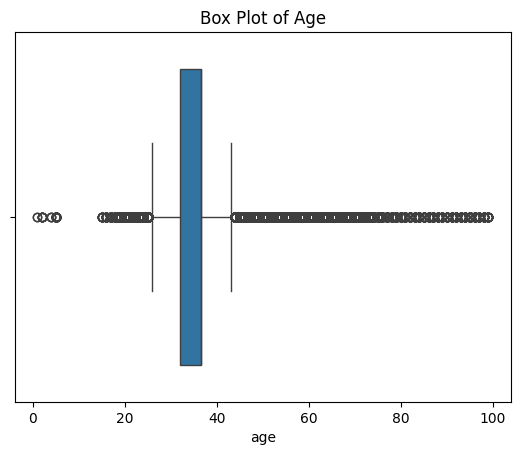

In [ ]:
sns.boxplot(x=train_users['age'])
plt.title('Box Plot of Age')
plt.show()

In [ ]:
def clean_outliers(train_users, column):
    Q1 = train_users[column].quantile(0.25)
    Q3 = train_users[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = train_users[(train_users[column] < lower_bound) | (train_users[column] > upper_bound)][column]
    print(f"Num of Outliers: {len(outliers)}")
    print(f"MIN: {lower_bound}")
    print(f"MAX: {upper_bound}")
    train_users[column] = train_users[column].clip(lower=lower_bound, upper=upper_bound)
    return train_users
train_users = clean_outliers(train_users, 'age')

Num of Outliers: 43233
MIN: 25.20359493053863
MAX: 43.32734178243561


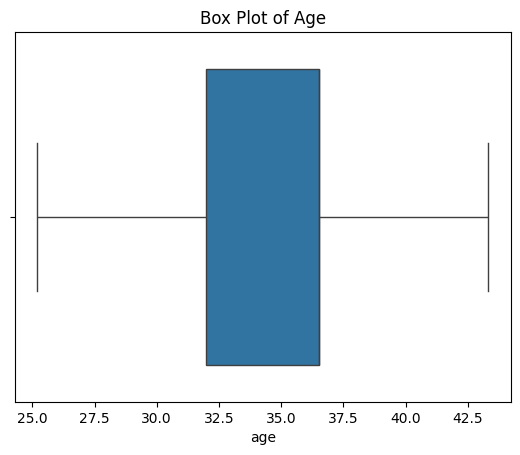

In [ ]:
sns.boxplot(x=train_users['age'])
plt.title('Box Plot of Age')
plt.show()

In [ ]:
train_users

,id,date_first_booking,gender,age,signup_method,signup_flow,affiliate_channel,affiliate_provider,first_affiliate_tracked,signup_app,first_device_type,first_browser,country_destination,year_created,month_created,day_created,year_booking,month_booking,day_booking
0,gxn3p5htnn,NaT,-unknown-,36.530937,facebook,0,direct,direct,untracked,Web,Mac Desktop,Chrome,NDF,2010,6,28,2013,5,15
1,820tgsjxq7,NaT,MALE,38.000000,facebook,0,seo,google,untracked,Web,Mac Desktop,Chrome,NDF,2011,5,25,2013,5,15
2,4ft3gnwmtx,2010-08-02,FEMALE,43.327342,basic,3,direct,direct,untracked,Web,Windows Desktop,IE,US,2010,9,28,2010,8,2
3,bjjt8pjhuk,2012-09-08,FEMALE,42.000000,facebook,0,direct,direct,untracked,Web,Mac Desktop,Firefox,other,2011,12,5,2012,9,8
4,87mebub9p4,2010-02-18,-unknown-,41.000000,basic,0,direct,direct,untracked,Web,Mac Desktop,Chrome,US,2010,9,14,2010,2,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
213446,zxodksqpep,NaT,MALE,32.000000,basic,0,sem-brand,google,omg,Web,Mac Desktop,Safari,NDF,2014,6,30,2013,5,15
213447,mhewnxesx9,NaT,-unknown-,36.530937,basic,0,direct,direct,linked,Web,Windows Desktop,Chrome,NDF,2014,6,30,2013,5,15
213448,6o3arsjbb4,NaT,-unknown-,32.000000,basic,0,direct,direct,untracked,Web,Mac Desktop,Firefox,NDF,2014,6,30,2013,5,15
213449,jh95kwisub,NaT,-unknown-,36.530937,basic,25,other,other,tracked-other,iOS,iPhone,Mobile Safari,NDF,2014,6,30,2013,5,15


In [ ]:
train_users['first_affiliate_tracked'].value_counts()

,count
first_affiliate_tracked,
untracked,109232
linked,46287
omg,43982
tracked-other,6156
product,1556
marketing,139
local ops,34


In [ ]:
mode_value = train_users['first_affiliate_tracked'].mode()[0]
train_users['first_affiliate_tracked'] = train_users['first_affiliate_tracked'].fillna(mode_value)

In [ ]:
train_users['first_affiliate_tracked'].value_counts()

,count
first_affiliate_tracked,
untracked,115297
linked,46287
omg,43982
tracked-other,6156
product,1556
marketing,139
local ops,34


In [ ]:
train_users['gender'].value_counts()

,count
gender,
-unknown-,95688
FEMALE,63041
MALE,54440
OTHER,282


In [ ]:
train_users['gender'] = train_users['gender'].replace('-unknown-', 'Unknown')

In [ ]:
train_users['signup_method'].value_counts()

,count
signup_method,
basic,152897
facebook,60008
google,546


In [ ]:
train_users['signup_flow'].value_counts()

,count
signup_flow,
0,164739
25,14659
12,9329
3,8822
2,6881
24,4328
23,2835
1,1047
6,301


In [ ]:
train_users

,id,date_first_booking,gender,age,signup_method,signup_flow,affiliate_channel,affiliate_provider,first_affiliate_tracked,signup_app,first_device_type,first_browser,country_destination,year_created,month_created,day_created,year_booking,month_booking,day_booking
0,gxn3p5htnn,NaT,Unknown,36.530937,facebook,0,direct,direct,untracked,Web,Mac Desktop,Chrome,NDF,2010,6,28,2013,5,15
1,820tgsjxq7,NaT,MALE,38.000000,facebook,0,seo,google,untracked,Web,Mac Desktop,Chrome,NDF,2011,5,25,2013,5,15
2,4ft3gnwmtx,2010-08-02,FEMALE,43.327342,basic,3,direct,direct,untracked,Web,Windows Desktop,IE,US,2010,9,28,2010,8,2
3,bjjt8pjhuk,2012-09-08,FEMALE,42.000000,facebook,0,direct,direct,untracked,Web,Mac Desktop,Firefox,other,2011,12,5,2012,9,8
4,87mebub9p4,2010-02-18,Unknown,41.000000,basic,0,direct,direct,untracked,Web,Mac Desktop,Chrome,US,2010,9,14,2010,2,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
213446,zxodksqpep,NaT,MALE,32.000000,basic,0,sem-brand,google,omg,Web,Mac Desktop,Safari,NDF,2014,6,30,2013,5,15
213447,mhewnxesx9,NaT,Unknown,36.530937,basic,0,direct,direct,linked,Web,Windows Desktop,Chrome,NDF,2014,6,30,2013,5,15
213448,6o3arsjbb4,NaT,Unknown,32.000000,basic,0,direct,direct,untracked,Web,Mac Desktop,Firefox,NDF,2014,6,30,2013,5,15
213449,jh95kwisub,NaT,Unknown,36.530937,basic,25,other,other,tracked-other,iOS,iPhone,Mobile Safari,NDF,2014,6,30,2013,5,15


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
X = train_users[['signup_flow']]
y = train_users['country_destination']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestClassifier()
model.fit(X_train, y_train)
print(model.feature_importances_)

[1.]


*EDA*

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(x='country_destination', data=train_users,
              order=train_users['country_destination'].value_counts().index)
plt.title('Distribution of Country Destination')
plt.xlabel('Destination')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

# إظهار النسب المئوية
dest_counts = train_users['country_destination'].value_counts(normalize=True)*100
print("نسب الوجهات:\n", dest_counts)

NameError: name 'plt' is not defined

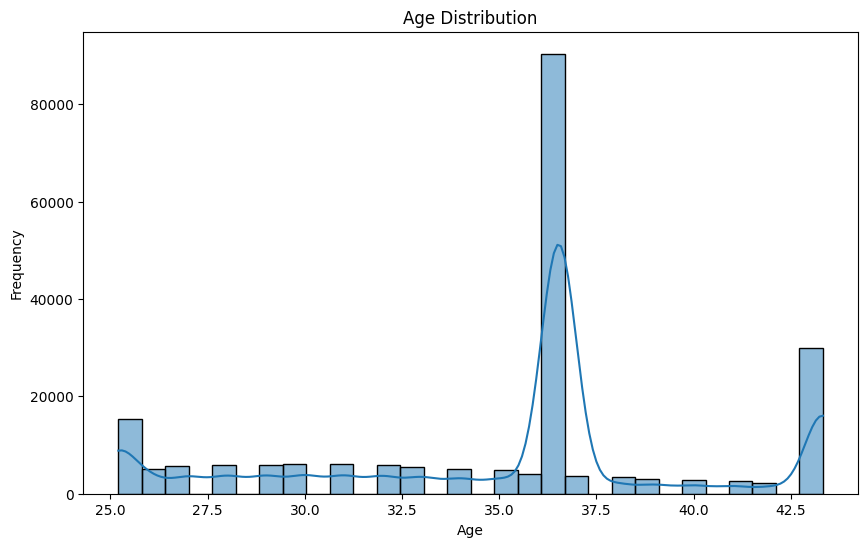

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(train_users['age'], bins=30, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

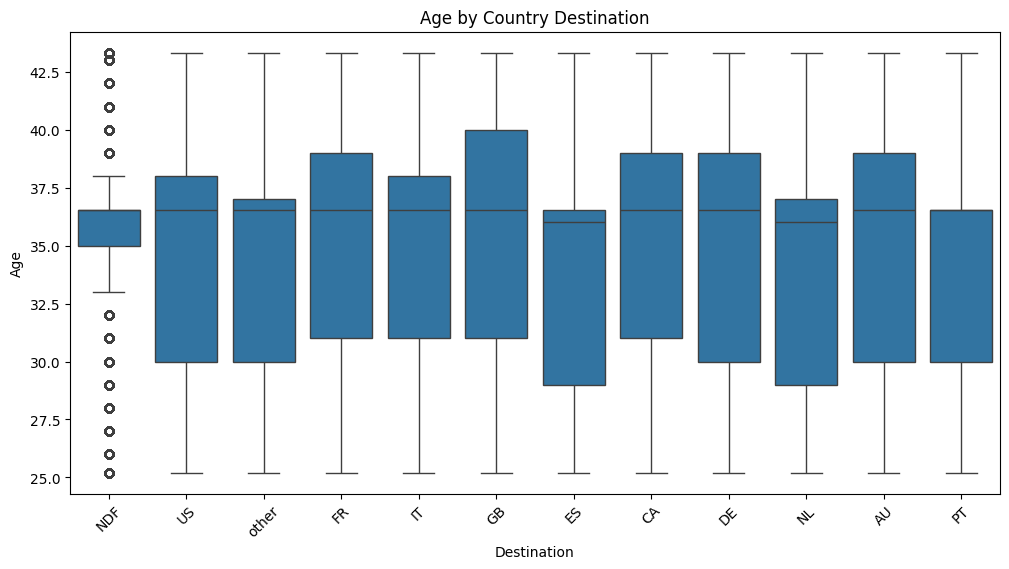

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(x='country_destination', y='age', data=train_users,
            order=train_users['country_destination'].value_counts().index)
plt.title('Age by Country Destination')
plt.xlabel('Destination')
plt.ylabel('Age')
plt.xticks(rotation=45)
plt.show()

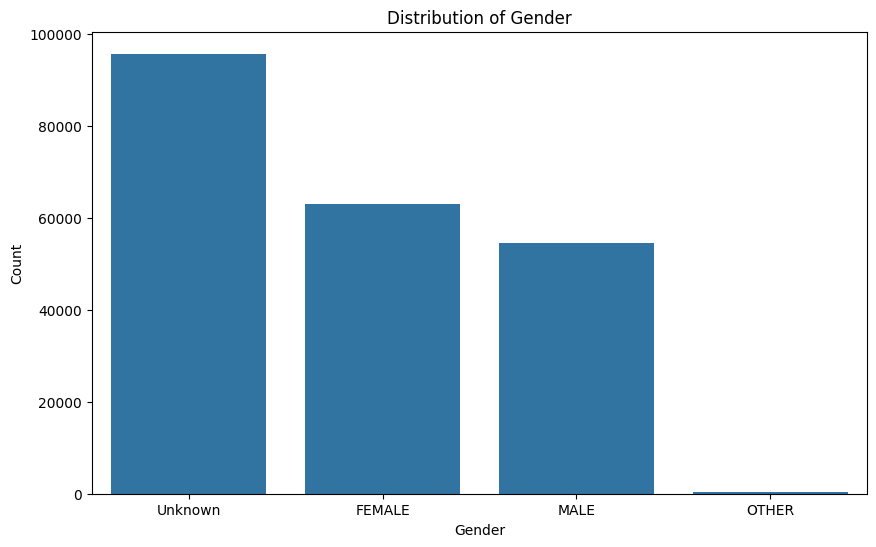

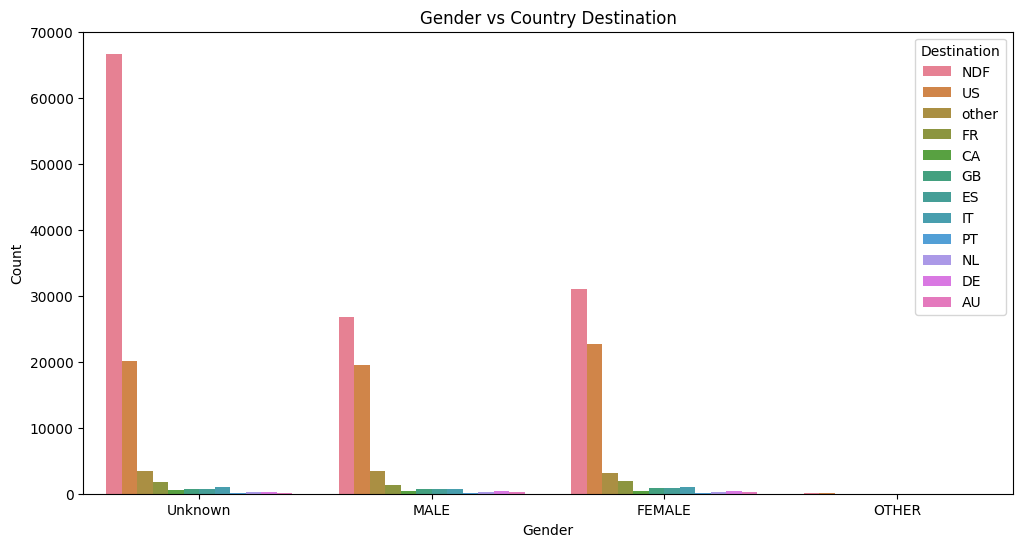

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(x='gender', data=train_users,
              order=train_users['gender'].value_counts().index)
plt.title('Distribution of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

# Relationship with destination
plt.figure(figsize=(12,6))
sns.countplot(x='gender', hue='country_destination', data=train_users)
plt.title('Gender vs Country Destination')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Destination')
plt.show()

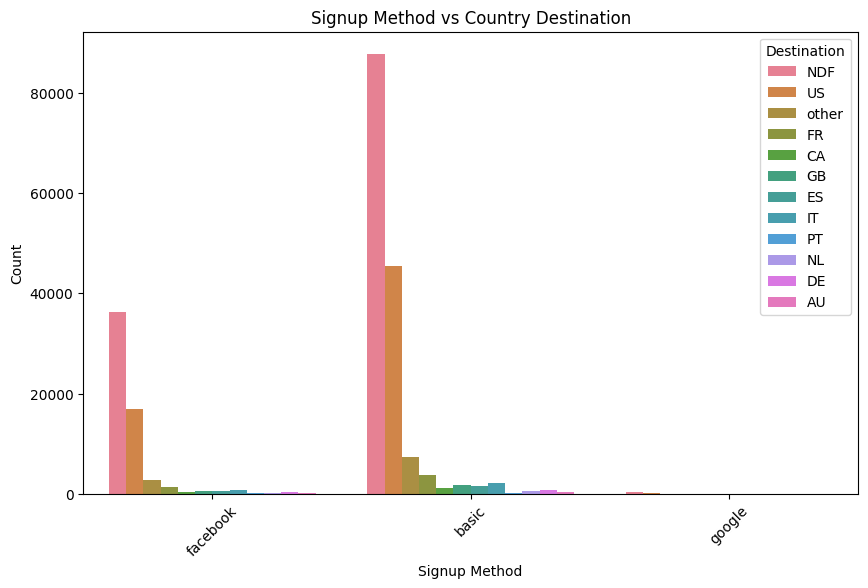

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(x='signup_method', hue='country_destination', data=train_users)
plt.title('Signup Method vs Country Destination')
plt.xlabel('Signup Method')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Destination')
plt.show()

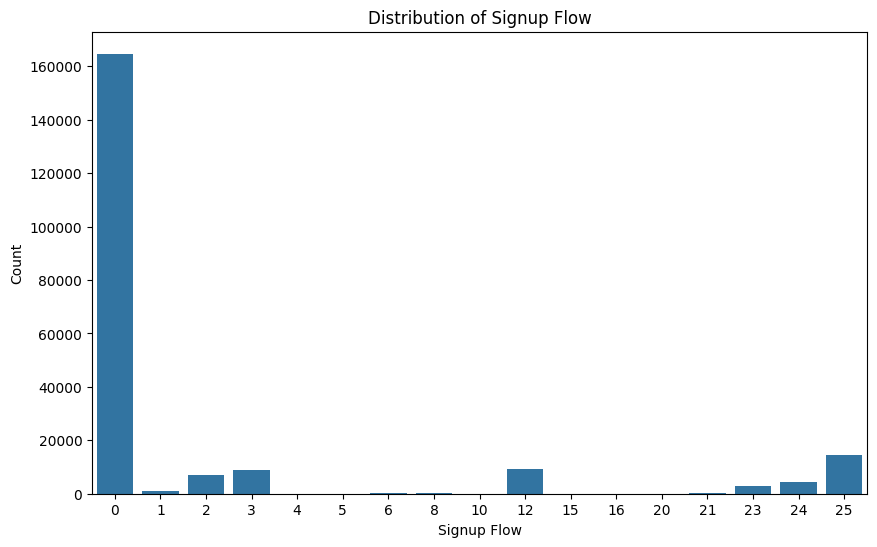

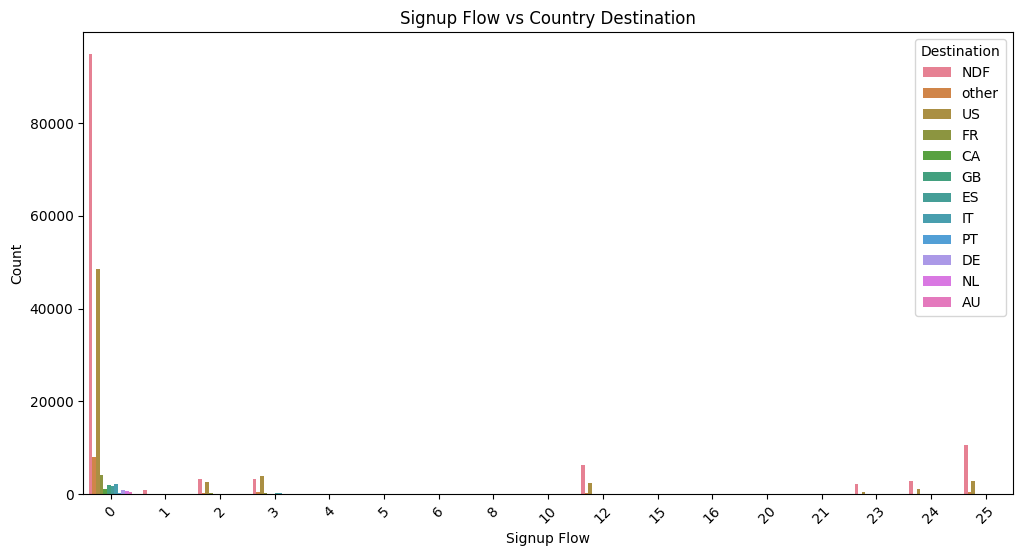

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(x='signup_flow', data=train_users)
plt.title('Distribution of Signup Flow')
plt.xlabel('Signup Flow')
plt.ylabel('Count')
plt.show()

# Relationship with destination
plt.figure(figsize=(12,6))
sns.countplot(x='signup_flow', hue='country_destination', data=train_users)
plt.title('Signup Flow vs Country Destination')
plt.xlabel('Signup Flow')
plt.ylabel('Count')
plt.legend(title='Destination')
plt.xticks(rotation=45)
plt.show()

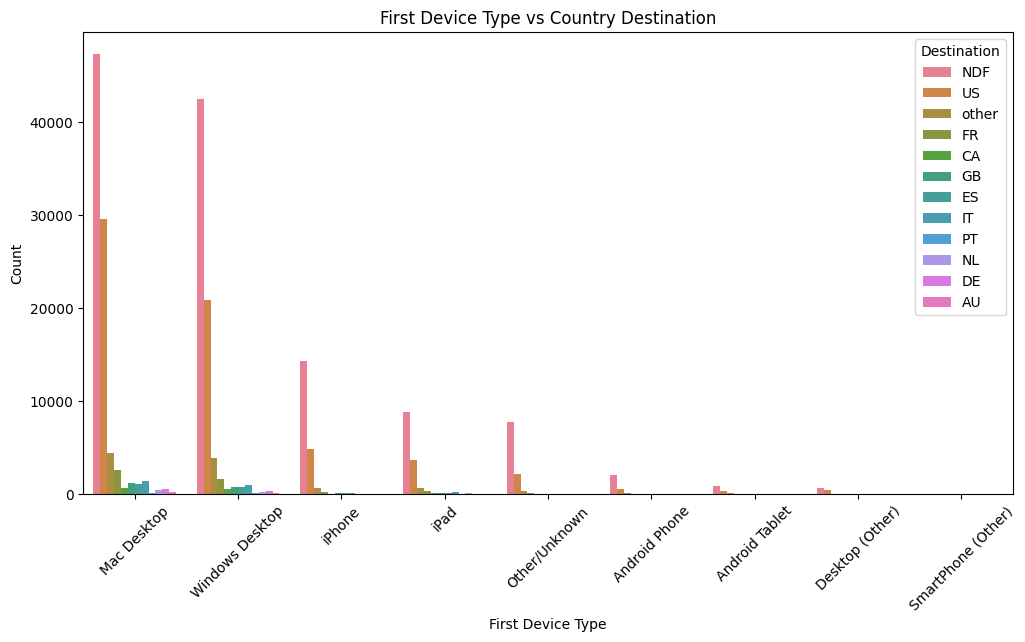

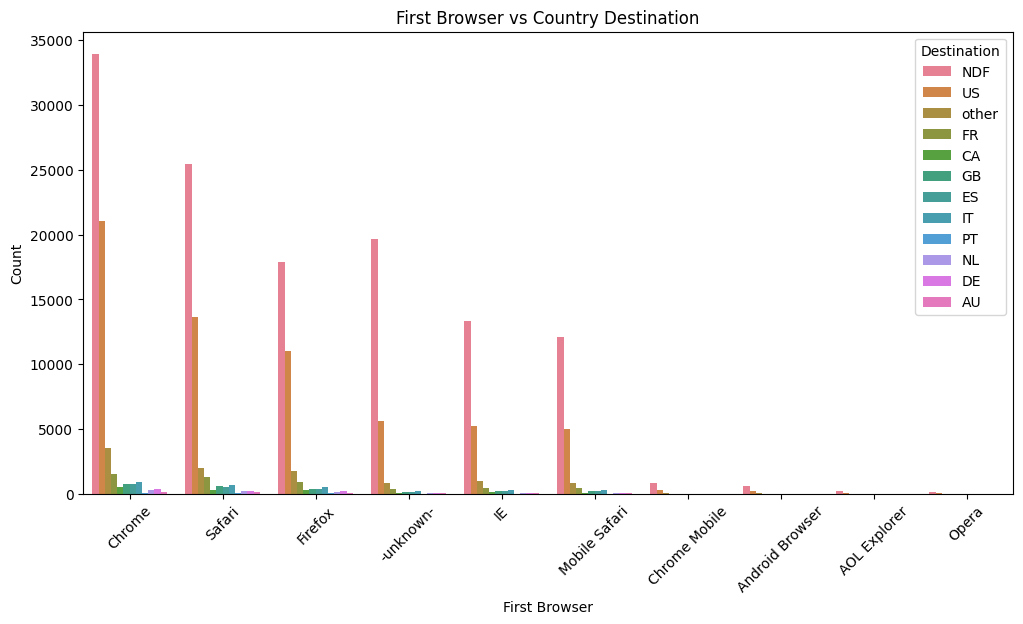

In [ ]:
plt.figure(figsize=(12,6))
sns.countplot(x='first_device_type', hue='country_destination', data=train_users,
              order=train_users['first_device_type'].value_counts().index)
plt.title('First Device Type vs Country Destination')
plt.xlabel('First Device Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Destination')
plt.show()

plt.figure(figsize=(12,6))
sns.countplot(x='first_browser', hue='country_destination', data=train_users,
              order=train_users['first_browser'].value_counts().index[:10])  # لعرض أهم 10 فقط
plt.title('First Browser vs Country Destination')
plt.xlabel('First Browser')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Destination')
plt.show()

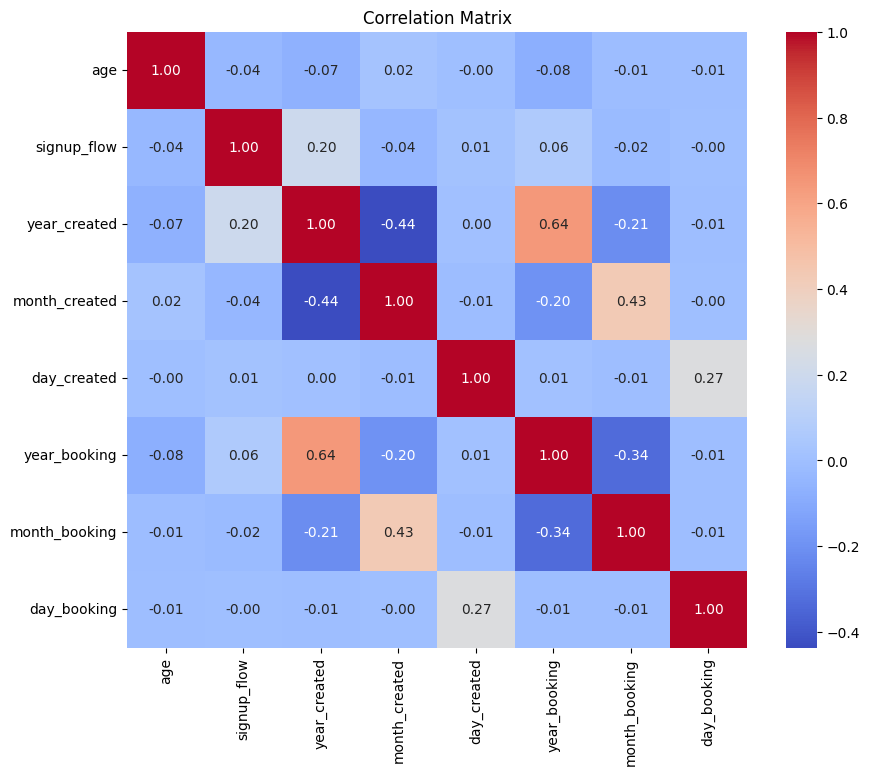

In [ ]:
num_cols = train_users.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(10,8))
sns.heatmap(train_users[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

# **Sessions**

In [ ]:
sessions

,user_id,action,action_type,action_detail,device_type,secs_elapsed
0,d1mm9tcy42,lookup,NaN,NaN,Windows Desktop,319.0
1,d1mm9tcy42,search_results,click,view_search_results,Windows Desktop,67753.0
2,d1mm9tcy42,lookup,NaN,NaN,Windows Desktop,301.0
3,d1mm9tcy42,search_results,click,view_search_results,Windows Desktop,22141.0
4,d1mm9tcy42,lookup,NaN,NaN,Windows Desktop,435.0
...,...,...,...,...,...,...
10567732,9uqfg8txu3,dashboard,view,dashboard,Windows Desktop,556.0
10567733,9uqfg8txu3,edit,view,edit_profile,Windows Desktop,6624.0
10567734,9uqfg8txu3,webcam_upload,-unknown-,-unknown-,Windows Desktop,200125.0
10567735,9uqfg8txu3,active,-unknown-,-unknown-,-unknown-,17624.0


In [ ]:
sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10567737 entries, 0 to 10567736
Data columns (total 6 columns):
 #   Column         Dtype  
---  ------         -----  
 0   user_id        object 
 1   action         object 
 2   action_type    object 
 3   action_detail  object 
 4   device_type    object 
 5   secs_elapsed   float64
dtypes: float64(1), object(5)
memory usage: 483.8+ MB


In [ ]:
sessions.isna().sum()/len(sessions)*100

,0
user_id,0.326428
action,0.753482
action_type,10.657003
action_detail,10.657003
device_type,0.000000
secs_elapsed,1.287229


In [ ]:
sessions['action'].value_counts()

,count
action,
show,2768278
index,843699
search_results,725226
personalize,706824
search,536057
...,...
deauthorize,1
events,1
reactivate,1


In [ ]:
sessions = sessions.dropna(subset=['user_id'])

In [ ]:
sessions['action'].fillna('unknown', inplace=True)

<ipython-input-59-48b514b057c2>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sessions['action'].fillna('unknown', inplace=True)


In [ ]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='most_frequent')
sessions[['action_type', 'action_detail']] = imputer.fit_transform(sessions[['action_type', 'action_detail']])

In [ ]:
sessions['secs_elapsed'].describe()

,secs_elapsed
count,1.043171e+07
mean,1.940581e+04
std,8.888424e+04
min,0.000000e+00
25%,2.290000e+02
50%,1.147000e+03
75%,8.444000e+03
max,1.799977e+06


In [ ]:
sessions['secs_elapsed'].fillna(sessions['secs_elapsed'].median(), inplace=True)

<ipython-input-66-0d86bfa9ca0a>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sessions['secs_elapsed'].fillna(sessions['secs_elapsed'].median(), inplace=True)


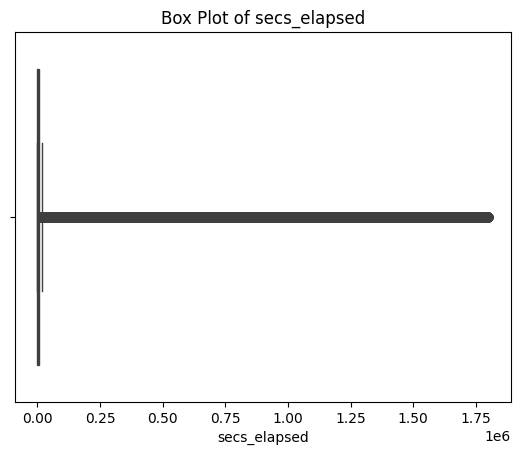

In [ ]:
sns.boxplot(x=sessions['secs_elapsed'])
plt.title('Box Plot of secs_elapsed')
plt.show()

In [ ]:
Q1 = sessions['secs_elapsed'].quantile(0.25)
Q3 = sessions['secs_elapsed'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

sessions['secs_elapsed'] = sessions['secs_elapsed'].clip(lower=lower_bound, upper=upper_bound)

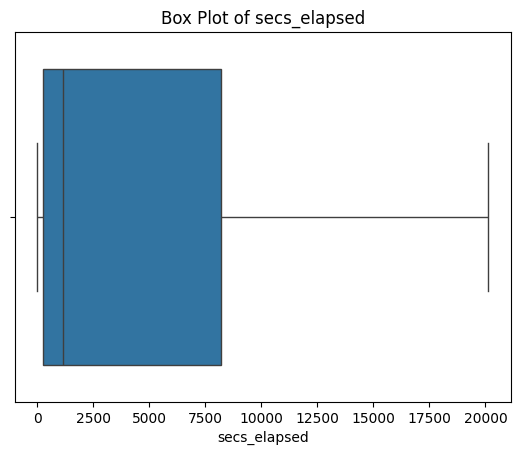

In [ ]:
sns.boxplot(x=sessions['secs_elapsed'])
plt.title('Box Plot of secs_elapsed')
plt.show()

In [ ]:
sessions.isna().sum()/sessions.shape[0]

,0
user_id,0.0
action,0.0
action_type,0.0
action_detail,0.0
device_type,0.0
secs_elapsed,0.0


In [ ]:
sessions['action_type'] = sessions['action_type'].replace({'-unknown-': 'Unknown'})

<ipython-input-77-e45cc04aa1e1>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sessions['action_type'] = sessions['action_type'].replace({'-unknown-': 'Unknown'})


In [ ]:
sessions['action_type'].value_counts()

,count
action_type,
view,4181966
data,1959171
click,1727557
Unknown,946619
submit,531188
message_post,68714
partner_callback,18656
booking_request,18555
modify,984


In [ ]:
sessions['action_detail'].value_counts()

,count
action_detail,
view_search_results,2479472
p3,1197940
-unknown-,946590
wishlist_content_update,673558
user_profile,603069
...,...
special_offer_field,3
host_refund_guest,2
host_respond_page,2


In [ ]:
sessions['device_type'].value_counts()

,count
device_type,
Mac Desktop,3228772
Windows Desktop,2374740
iPhone,1862692
Android Phone,770269
iPad Tablet,601272
Android App Unknown Phone/Tablet,247659
-unknown-,186228
Tablet,126287
Linux Desktop,25172


In [ ]:
cat_cols = ['action', 'action_type', 'action_detail', 'device_type']
for col in cat_cols:
    print(col, "has", sessions[col].nunique(), "unique values.")

action has 360 unique values.
action_type has 10 unique values.
action_detail has 155 unique values.
device_type has 14 unique values.


In [ ]:
sessions

,user_id,action,action_type,action_detail,device_type,secs_elapsed
0,d1mm9tcy42,lookup,view,view_search_results,Windows Desktop,319.0
1,d1mm9tcy42,search_results,click,view_search_results,Windows Desktop,20127.0
2,d1mm9tcy42,lookup,view,view_search_results,Windows Desktop,301.0
4,d1mm9tcy42,lookup,view,view_search_results,Windows Desktop,435.0
5,d1mm9tcy42,search_results,click,view_search_results,Windows Desktop,7703.0
...,...,...,...,...,...,...
10567732,9uqfg8txu3,dashboard,view,dashboard,Windows Desktop,556.0
10567733,9uqfg8txu3,edit,view,edit_profile,Windows Desktop,6624.0
10567734,9uqfg8txu3,webcam_upload,Unknown,-unknown-,Windows Desktop,20127.0
10567735,9uqfg8txu3,active,Unknown,-unknown-,-unknown-,17624.0


In [ ]:
sessions_agg = sessions.groupby('user_id').agg({
    'action': 'count',
    'secs_elapsed': 'sum',
    'action_type': lambda x: x.nunique()
}).reset_index()
sessions_agg.columns = ['id', 'num_sessions', 'total_secs', 'unique_action_types']
print(sessions_agg.head())

           id  num_sessions  total_secs  unique_action_types
0  00023iyk9l            40    175115.0                    6
1  0010k6l0om            58    207116.0                    5
2  001wyh0pz8            89    251880.0                    5
3  0028jgx1x1            28    128132.0                    5
4  002qnbzfs5           713   1887078.0                    7


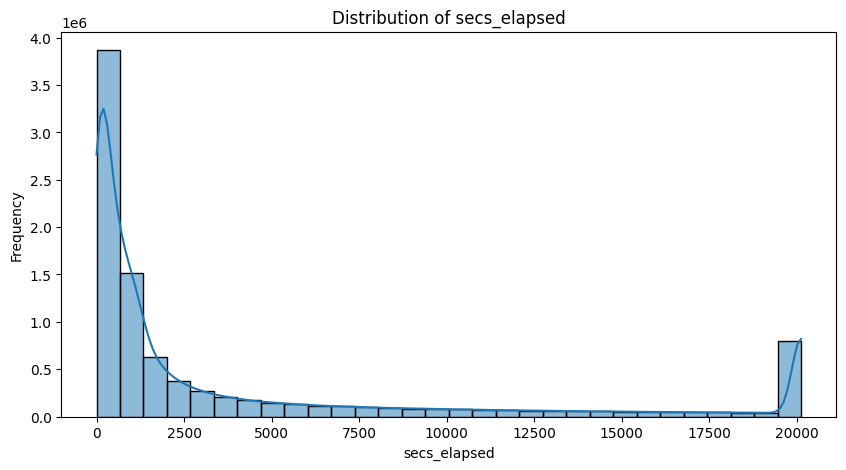

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(sessions['secs_elapsed'], bins=30, kde=True)
plt.title('Distribution of secs_elapsed')
plt.xlabel('secs_elapsed')
plt.ylabel('Frequency')
plt.show()

In [ ]:
test_users

,id,date_account_created,timestamp_first_active,date_first_booking,gender,age,signup_method,signup_flow,language,affiliate_channel,affiliate_provider,first_affiliate_tracked,signup_app,first_device_type,first_browser
0,5uwns89zht,2014-07-01,20140701000006,NaN,FEMALE,35.0,facebook,0,en,direct,direct,untracked,Moweb,iPhone,Mobile Safari
1,jtl0dijy2j,2014-07-01,20140701000051,NaN,-unknown-,NaN,basic,0,en,direct,direct,untracked,Moweb,iPhone,Mobile Safari
2,xx0ulgorjt,2014-07-01,20140701000148,NaN,-unknown-,NaN,basic,0,en,direct,direct,linked,Web,Windows Desktop,Chrome
3,6c6puo6ix0,2014-07-01,20140701000215,NaN,-unknown-,NaN,basic,0,en,direct,direct,linked,Web,Windows Desktop,IE
4,czqhjk3yfe,2014-07-01,20140701000305,NaN,-unknown-,NaN,basic,0,en,direct,direct,untracked,Web,Mac Desktop,Safari
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62091,cv0na2lf5a,2014-09-30,20140930235232,NaN,-unknown-,31.0,basic,0,en,direct,direct,untracked,Web,Windows Desktop,IE
62092,zp8xfonng8,2014-09-30,20140930235306,NaN,-unknown-,NaN,basic,23,ko,direct,direct,untracked,Android,Android Phone,-unknown-
62093,fa6260ziny,2014-09-30,20140930235408,NaN,-unknown-,NaN,basic,0,de,direct,direct,linked,Web,Windows Desktop,Firefox
62094,87k0fy4ugm,2014-09-30,20140930235430,NaN,-unknown-,NaN,basic,0,en,sem-brand,google,omg,Web,Mac Desktop,Safari


In [ ]:
test_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62096 entries, 0 to 62095
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       62096 non-null  object 
 1   date_account_created     62096 non-null  object 
 2   date_first_booking       0 non-null      float64
 3   gender                   62096 non-null  object 
 4   age                      33220 non-null  float64
 5   signup_method            62096 non-null  object 
 6   signup_flow              62096 non-null  int64  
 7   affiliate_channel        62096 non-null  object 
 8   affiliate_provider       62096 non-null  object 
 9   first_affiliate_tracked  62076 non-null  object 
 10  signup_app               62096 non-null  object 
 11  first_device_type        62096 non-null  object 
 12  first_browser            62096 non-null  object 
dtypes: float64(2), int64(1), object(10)
memory usage: 6.2+ MB


In [ ]:
test_users.isna().sum()/test_users.shape[0]

,0
id,0.000000
date_account_created,0.000000
timestamp_first_active,0.000000
date_first_booking,1.000000
gender,0.000000
age,0.465022
signup_method,0.000000
signup_flow,0.000000
language,0.000000
affiliate_channel,0.000000


In [ ]:
test_users.drop('timestamp_first_active', axis=1, inplace=True)
test_users.drop('language', axis=1, inplace=True)

In [ ]:
test_users['date_account_created'] = pd.to_datetime(test_users['date_account_created'])
test_users['year_created'] = test_users['date_account_created'].dt.year
test_users['month_created'] = test_users['date_account_created'].dt.month
test_users['day_created'] = test_users['date_account_created'].dt.day

In [ ]:
test_users = test_users.drop('date_account_created', axis=1)

In [ ]:
test_users.drop('day_booking', axis=1, inplace=True)

In [ ]:
test_users.isna().sum()/test_users.shape[0]

,0
id,0.000000
gender,0.000000
age,0.465022
signup_method,0.000000
signup_flow,0.000000
affiliate_channel,0.000000
affiliate_provider,0.000000
first_affiliate_tracked,0.000322
signup_app,0.000000
first_device_type,0.000000


In [ ]:
test_users['age'].describe()

,age
count,33220.000000
mean,37.616677
std,74.440647
min,1.000000
25%,26.000000
50%,31.000000
75%,40.000000
max,2002.000000


In [ ]:
test_users['age'].value_counts()

,count
age,
28.0,1748
27.0,1724
26.0,1701
25.0,1690
29.0,1684
...,...
1945.0,1
2000.0,1
1938.0,1


In [ ]:
test_users['age'] = test_users['age'].apply(lambda x: x if x < 100 else np.nan)

In [ ]:
test_users['age'].value_counts()

,count
age,
28.0,1748
27.0,1724
26.0,1701
25.0,1690
29.0,1684
...,...
91.0,2
99.0,2
98.0,2


In [ ]:
from sklearn.impute import KNNImputer
imputer0 = KNNImputer(n_neighbors=5)
test_users[['age']] = imputer0.fit_transform(test_users[['age']])

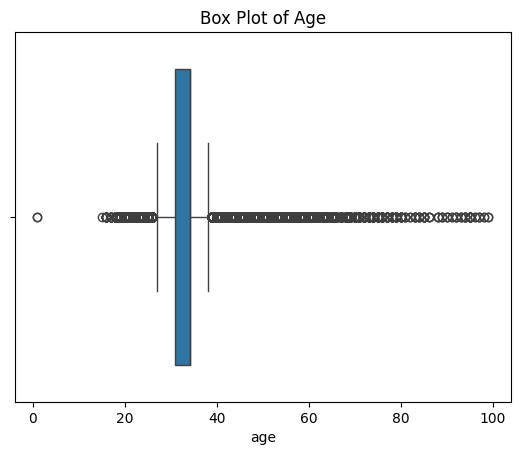

In [ ]:
sns.boxplot(x=test_users['age'])
plt.title('Box Plot of Age')
plt.show()

In [ ]:
def clean_outliers0(test_users, column):
    Q1 = test_users[column].quantile(0.25)
    Q3 = test_users[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = test_users[(test_users[column] < lower_bound) | (test_users[column] > upper_bound)][column]
    print(f"Num of Outliers: {len(outliers)}")
    print(f"MIN: {lower_bound}")
    print(f"MAX: {upper_bound}")
    test_users[column] = test_users[column].clip(lower=lower_bound, upper=upper_bound)
    return test_users
test_users = clean_outliers(test_users, 'age')

Num of Outliers: 17330
MIN: 26.266489199878304
MAX: 38.8891846668695


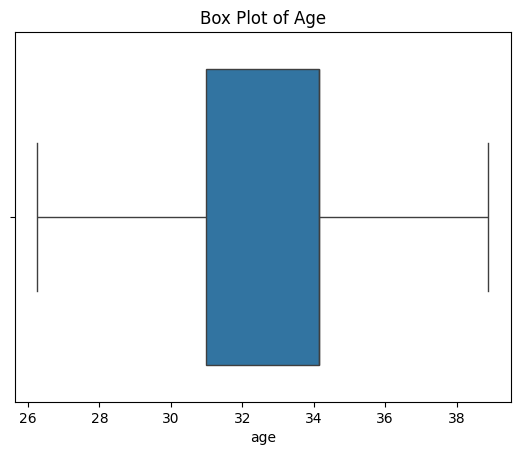

In [ ]:
sns.boxplot(x=test_users['age'])
plt.title('Box Plot of Age')
plt.show()

In [ ]:
test_users

,id,gender,age,signup_method,signup_flow,affiliate_channel,affiliate_provider,first_affiliate_tracked,signup_app,first_device_type,first_browser,year_created,month_created,day_created
0,5uwns89zht,FEMALE,35.000000,facebook,0,direct,direct,untracked,Moweb,iPhone,Mobile Safari,2014,7,1
1,jtl0dijy2j,-unknown-,34.155674,basic,0,direct,direct,untracked,Moweb,iPhone,Mobile Safari,2014,7,1
2,xx0ulgorjt,-unknown-,34.155674,basic,0,direct,direct,linked,Web,Windows Desktop,Chrome,2014,7,1
3,6c6puo6ix0,-unknown-,34.155674,basic,0,direct,direct,linked,Web,Windows Desktop,IE,2014,7,1
4,czqhjk3yfe,-unknown-,34.155674,basic,0,direct,direct,untracked,Web,Mac Desktop,Safari,2014,7,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62091,cv0na2lf5a,-unknown-,31.000000,basic,0,direct,direct,untracked,Web,Windows Desktop,IE,2014,9,30
62092,zp8xfonng8,-unknown-,34.155674,basic,23,direct,direct,untracked,Android,Android Phone,-unknown-,2014,9,30
62093,fa6260ziny,-unknown-,34.155674,basic,0,direct,direct,linked,Web,Windows Desktop,Firefox,2014,9,30
62094,87k0fy4ugm,-unknown-,34.155674,basic,0,sem-brand,google,omg,Web,Mac Desktop,Safari,2014,9,30


In [ ]:
mode_value = test_users['first_affiliate_tracked'].mode()[0]
test_users['first_affiliate_tracked'] = test_users['first_affiliate_tracked'].fillna(mode_value)

In [ ]:
train_users_backup = train_users.copy()
test_users_backup = test_users.copy()
sessions_backup = sessions.copy()

# Merge Data

In [ ]:
train_users_merged = train_users.merge(sessions_agg, on='id', how='left')
test_users_merged = test_users.merge(sessions_agg, on='id', how='left')
print(train_users_merged.head())
print(test_users_merged.head())

           id date_first_booking   gender        age signup_method  \
0  gxn3p5htnn                NaT  Unknown  36.530937      facebook   
1  820tgsjxq7                NaT     MALE  38.000000      facebook   
2  4ft3gnwmtx         2010-08-02   FEMALE  43.327342         basic   
3  bjjt8pjhuk         2012-09-08   FEMALE  42.000000      facebook   
4  87mebub9p4         2010-02-18  Unknown  41.000000         basic   

   signup_flow affiliate_channel affiliate_provider first_affiliate_tracked  \
0            0            direct             direct               untracked   
1            0               seo             google               untracked   
2            3            direct             direct               untracked   
3            0            direct             direct               untracked   
4            0            direct             direct               untracked   

  signup_app first_device_type first_browser country_destination  \
0        Web       Mac Desktop      

In [ ]:
cols_to_fill = ['num_sessions', 'total_secs', 'unique_action_types']
train_users_merged[cols_to_fill] = train_users_merged[cols_to_fill].fillna(0)
test_users_merged[cols_to_fill] = test_users_merged[cols_to_fill].fillna(0)

In [ ]:
print(train_users_merged[cols_to_fill].isna().sum())

num_sessions           0
total_secs             0
unique_action_types    0
dtype: int64


In [ ]:
print(test_users_merged[cols_to_fill].isna().sum())


num_sessions           0
total_secs             0
unique_action_types    0
dtype: int64


In [ ]:
categorical_cols = ['gender', 'signup_method', 'signup_flow',
                    'affiliate_channel', 'affiliate_provider',
                    'first_affiliate_tracked', 'signup_app',
                    'first_device_type', 'first_browser']

train_users_encoded = pd.get_dummies(train_users_merged, columns=categorical_cols, drop_first=True)

test_users_encoded = pd.get_dummies(test_users_merged, columns=categorical_cols, drop_first=True)

train_users_encoded, test_users_encoded = train_users_encoded.align(test_users_encoded, join='inner', axis=1)

train_users_encoded['country_destination'] = train_users_merged['country_destination']

print("Train columns:", train_users_encoded.columns)
print("Test columns:", test_users_encoded.columns)


Train columns: Index(['id', 'age', 'year_created', 'month_created', 'day_created',
       'num_sessions', 'total_secs', 'unique_action_types', 'gender_MALE',
       'gender_OTHER', 'signup_method_facebook', 'signup_method_google',
       'signup_flow_8', 'signup_flow_12', 'signup_flow_21', 'signup_flow_23',
       'signup_flow_25', 'affiliate_channel_direct', 'affiliate_channel_other',
       'affiliate_channel_remarketing', 'affiliate_channel_sem-brand',
       'affiliate_channel_sem-non-brand', 'affiliate_channel_seo',
       'affiliate_provider_bing', 'affiliate_provider_craigslist',
       'affiliate_provider_daum', 'affiliate_provider_direct',
       'affiliate_provider_email-marketing', 'affiliate_provider_facebook',
       'affiliate_provider_facebook-open-graph', 'affiliate_provider_google',
       'affiliate_provider_gsp', 'affiliate_provider_meetup',
       'affiliate_provider_naver', 'affiliate_provider_other',
       'affiliate_provider_padmapper', 'affiliate_provider_vast'

In [ ]:
from sklearn.model_selection import train_test_split
X = train_users_encoded.drop('country_destination', axis=1)
y = train_users_encoded['country_destination']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Train shape: (170760, 83)
Validation shape: (42691, 83)


In [ ]:
X_train = X_train.drop('id', axis=1)
X_val = X_val.drop('id', axis=1)

In [ ]:
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_val_encoded = le.transform(y_val)

model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')
model.fit(X_train, y_train_encoded)

y_val_pred = model.predict(X_val)

print("Initial Validation Accuracy:", accuracy_score(y_val_encoded, y_val_pred))
print("Initial Classification Report:")
print(classification_report(y_val_encoded, y_val_pred, target_names=le.classes_))

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:41:48] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Initial Validation Accuracy: 0.6421493991707854
Initial Classification Report:
              precision    recall  f1-score   support

          AU       0.00      0.00      0.00       114
          CA       0.00      0.00      0.00       275
          DE       0.00      0.00      0.00       208
          ES       0.33      0.00      0.00       451
          FR       1.00      0.00      0.00      1010
          GB       0.00      0.00      0.00       497
          IT       0.00      0.00      0.00       562
         NDF       0.70      0.86      0.77     24843
          NL       0.00      0.00      0.00       155
          PT       1.00      0.02      0.04        45
          US       0.50      0.49      0.50     12525
       other       0.00      0.00      0.00      2006

    accuracy                           0.64     42691
   macro avg       0.29      0.11      0.11     42691
weighted avg       0.58      0.64      0.59     42691



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)

model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

grid_search = GridSearchCV(model, param_grid, scoring='accuracy', cv=3, n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train_encoded)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

best_model = grid_search.best_estimator_


Fitting 3 folds for each of 243 candidates, totalling 729 fits


/usr/local/lib/python3.11/dist-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [10:07:17] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Best Parameters: {'colsample_bytree': 0.7, 'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}
Best CV Accuracy: 0.6419360505973296


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Fix: best_model was trained on encoded (numeric) labels, so encode y_val
# the same way before comparing. Comparing string labels to numeric predictions
# is what crashed this cell and made the accuracy print 0.0.
y_val_encoded = le.transform(y_val)
y_val_pred = best_model.predict(X_val)

accuracy = accuracy_score(y_val_encoded, y_val_pred)
print("Final Validation Accuracy:", accuracy)

print("Final Classification Report:")
print(classification_report(y_val_encoded, y_val_pred, target_names=le.classes_))

cm = confusion_matrix(y_val_encoded, y_val_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
